# Trabajo Práctico — Aprendizaje Automático III
**Tema:** MNIST con Redes Neuronales (búsqueda de hiperparámetros sin keras-tuner)

**Objetivos:**
- Realizar EDA y visualizaciones iniciales sobre MNIST.
- Preprocesar y dividir correctamente el dataset en `X_train, y_train`, `X_val, y_val`, `X_test, y_test`.
- Diseñar y entrenar modelos (MLP / CNN), buscando **hiperparámetros** con bucles (for/while) o Grid “manual” (sin keras-tuner).
- Evaluar: **Accuracy** e **Intervalo de Confianza 95%** para datos nuevos.
- Graficar **curvas de aprendizaje** y comentarlas.
- Hacer **predicciones** puntuales (`X_test[50]`, `X_test[150]`).
- Entrenar **modelo de producción** y guardarlo a archivo.
- Reducir variables a **200** (Mutual Information) + **mapa de calor** de importancia.
- Re-entrenar con los 200 mejores píxeles y **comparar**


In [ ]:
# Fuerza un entorno compatible (TensorFlow 2.15 + NumPy 1.26 + scikit-learn 1.3 + SciPy 1.11)
!pip install --quiet --no-cache-dir --upgrade --force-reinstall \
  "numpy==1.26.4" \
  "scipy==1.11.4" \
  "scikit-learn==1.3.2" \
  "matplotlib==3.8.4" \
  "tensorflow" # Removed version constraint

import os, time, sys
print("✅ Paquetes instalados. Reiniciando el runtime para aplicar versiones…")
time.sleep(1)
os.kill(os.getpid(), 9)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 kB 17.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 240.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 210.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 185.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 151.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 192.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 261.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 362.6/362.6 kB 317.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 216.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 163.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
!pip install -U scikit-learn tensorflow matplotlib numpy

  Using cached scikit_learn-1.7.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (11 kB)
  Using cached matplotlib-3.10.7-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (11 kB)
  Using cached numpy-2.3.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
Using cached scikit_learn-1.7.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.5 MB)
Using cached matplotlib-3.10.7-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.7 MB)
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.3.2
    Uninstalling scikit-learn-1.3.2:
      Successfully uninstalled scikit-learn-1.3.2
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.8.4
    Uninstalling matplotlib-3.8.4:
      Successfully uninstalled matplotlib-3.8.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the sourc

Usaremos: `tensorflow/keras` para las redes, `scikit-learn` para EDA, splits estratificados, métricas y **Mutual Information**. Fijamos **semillas** para reproducibilidad (dentro de lo posible).


In [ ]:
import os, random, math, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_selection import mutual_info_classif
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras.datasets import mnist

# Reproducibilidad
SEED = 123
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

def set_mpl():
    plt.rcParams["figure.figsize"] = (6,4)
    plt.rcParams["axes.grid"] = True

set_mpl()

def wilson_ci(p_hat, n, z=1.96):
    # Intervalo de confianza de Wilson para una proporción (accuracy)
    denom = 1 + (z**2)/n
    center = (p_hat + (z**2)/(2*n)) / denom
    margin = (z/denom) * math.sqrt( (p_hat*(1-p_hat)/n) + (z**2)/(4*n**2) )
    return center - margin, center + margin


MNIST: 70.000 imágenes 28×28 en escala de grises (10 clases: dígitos 0–9).
Keras provee: (X_train_full, y_train_full) y (X_test, y_test).
Luego partimos `train_full` en **train** y **val** de forma **estratificada** para mantener proporción de clases.


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shapes:
X_train_full: (60000, 28, 28) y_train_full: (60000,)
X_test: (10000, 28, 28) y_test: (10000,)


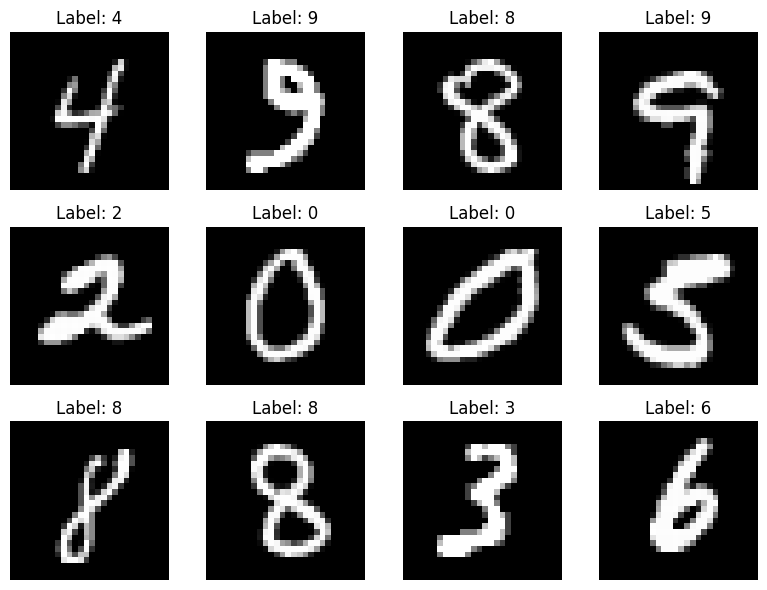

In [ ]:
(X_train_full, y_train_full), (X_test, y_test) = mnist.load_data()

print("Shapes:")
print("X_train_full:", X_train_full.shape, "y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

# Mosaico de 12 ejemplos
set_mpl()
fig, axes = plt.subplots(3,4, figsize=(8,6))
idxs = np.random.choice(len(X_train_full), 12, replace=False)
for ax, i in zip(axes.ravel(), idxs):
    ax.imshow(X_train_full[i], cmap='gray')
    ax.set_title(f"Label: {y_train_full[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()


1) Verificamos balance por clase.
2) Visualizamos un dígito puntual (p.ej. 7) para inspección cualitativa.


Distribución de clases en train_full: {5: 5421, 0: 5923, 4: 5842, 1: 6742, 9: 5949, 2: 5958, 3: 6131, 6: 5918, 7: 6265, 8: 5851}


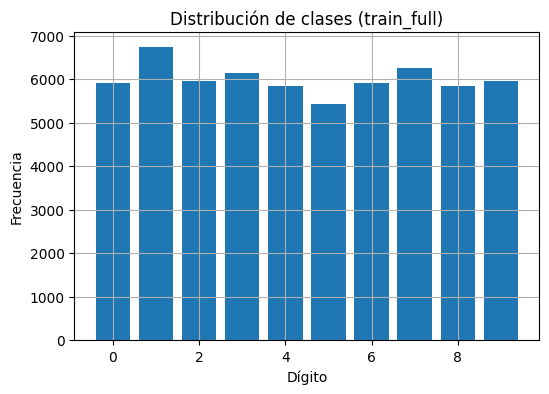

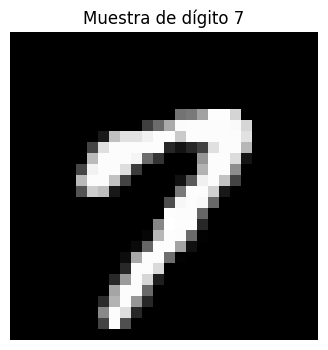

In [ ]:
import collections

cont = collections.Counter(y_train_full)
print("Distribución de clases en train_full:", dict(cont))

set_mpl()
plt.bar(cont.keys(), cont.values())
plt.title("Distribución de clases (train_full)")
plt.xlabel("Dígito"); plt.ylabel("Frecuencia")
plt.show()

numero = 7
pos = np.where(y_train_full == numero)[0][0]
plt.imshow(X_train_full[pos], cmap='gray')
plt.title(f"Muestra de dígito {numero}")
plt.axis('off')
plt.show()


- **Escalado**: Pasamos los píxeles a [0,1] dividiendo por 255 (mejora estabilidad numérica).
- **Split**: El conjunto original ya trae `test`. A partir de `train_full`, creamos **validación (10%)** con **StratifiedShuffleSplit** (mantiene proporción por clase).
- Definición pedida:
  - `X_train, y_train`: entrenamiento
  - `X_val, y_val`: validación (para elegir hiperparámetros)
  - `X_test, y_test`: prueba final (estimación de desempeño en datos nuevos)


In [ ]:
# Escalado a [0,1]
X_train_full_f = X_train_full.astype('float32') / 255.0
X_test_f       = X_test.astype('float32') / 255.0

# División estratificada para validación desde el train_full
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
train_idx, val_idx = next(sss.split(X_train_full_f, y_train_full))

X_train, y_train = X_train_full_f[train_idx], y_train_full[train_idx]
X_val,   y_val   = X_train_full_f[val_idx],   y_train_full[val_idx]
# X_test_f y y_test ya vienen dados

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test_f.shape)


X_train: (54000, 28, 28) X_val: (6000, 28, 28) X_test: (10000, 28, 28)


Entrenaremos dos familias:
- **MLP**: sencillo, rápido; baseline fuerte para MNIST.
- **CNN**: explota estructura espacial (convoluciones + pooling); suele rendir mejor.

Seleccionaremos hiperparámetros por **búsqueda manual** (rejilla pequeña) con **bucles for** (sin keras-tuner).
Criterio de selección: **máxima val_accuracy** con parada temprana para evitar sobreajuste y ahorrar cómputo.


In [ ]:
def build_mlp(input_shape=(28,28), hidden_units=[256,128], dropout=0.2, num_classes=10):
    model = keras.Sequential(name="MLP_MNIST")
    model.add(layers.Input(shape=input_shape))
    model.add(layers.Flatten())
    for u in hidden_units:
        model.add(layers.Dense(u, activation='relu'))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(num_classes, activation='softmax'))
    return model

def build_cnn(input_shape=(28,28,1), conv_blocks=[(32,3),(64,3)], dense_units=128, dropout=0.3, num_classes=10):
    inputs = keras.Input(shape=input_shape)
    x = inputs
    for f,k in conv_blocks:
        x = layers.Conv2D(f, kernel_size=k, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model = keras.Model(inputs, outputs, name="CNN_MNIST")
    return model

def compile_and_fit(model, X_tr, y_tr, X_va, y_va, lr=1e-3, batch_size=128, epochs=20, patience=5):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    es = callbacks.EarlyStopping(monitor='val_accuracy', patience=patience, restore_best_weights=True)
    hist = model.fit(X_tr, y_tr,
                     validation_data=(X_va, y_va),
                     epochs=epochs, batch_size=batch_size, verbose=2,
                     callbacks=[es])
    return model, hist


Usamos dos espacios de búsqueda acotados para que el tiempo sea razonable en Colab.
Guardamos el **mejor** según `val_accuracy`. Para CNN convertimos entrada a (28,28,1).


In [ ]:
search_space_mlp = [
    {"hidden_units":[[256,128],[512,256]], "dropout":[0.2,0.3], "lr":[1e-3,5e-4], "batch_size":[128,256], "epochs":[20]},
]

search_space_cnn = [
    {"conv_blocks":[[(32,3),(64,3)], [(32,3),(64,3),(64,3)]],
     "dense_units":[128,256], "dropout":[0.3,0.4], "lr":[1e-3,5e-4], "batch_size":[128], "epochs":[20]}
]

best = {"name":None, "val_acc":0.0, "cfg":None, "history":None, "model":None}

# 1) MLP
for cfg in search_space_mlp:
    for hu in cfg["hidden_units"]:
        for do in cfg["dropout"]:
            for lr in cfg["lr"]:
                for bs in cfg["batch_size"]:
                    print(f"[MLP] hu={hu} do={do} lr={lr} bs={bs}")
                    mlp = build_mlp(hidden_units=hu, dropout=do)
                    model, hist = compile_and_fit(mlp, X_train, y_train, X_val, y_val,
                                                  lr=lr, batch_size=bs, epochs=cfg["epochs"][0], patience=5)
                    val_acc = max(hist.history["val_accuracy"])
                    if val_acc > best["val_acc"]:
                        best = {"name":"MLP", "val_acc":val_acc, "cfg":{"hu":hu,"dropout":do,"lr":lr,"bs":bs},
                                "history":hist.history, "model":model}

# 2) CNN
X_train_cnn = X_train[..., None]
X_val_cnn   = X_val[..., None]

for cfg in search_space_cnn:
    for cb in cfg["conv_blocks"]:
        for du in cfg["dense_units"]:
            for do in cfg["dropout"]:
                for lr in cfg["lr"]:
                    for bs in cfg["batch_size"]:
                        print(f"[CNN] conv_blocks={cb} du={du} do={do} lr={lr} bs={bs}")
                        cnn = build_cnn(conv_blocks=cb, dense_units=du, dropout=do)
                        model, hist = compile_and_fit(cnn, X_train_cnn, y_train, X_val_cnn, y_val,
                                                      lr=lr, batch_size=bs, epochs=cfg["epochs"][0], patience=5)
                        val_acc = max(hist.history["val_accuracy"])
                        if val_acc > best["val_acc"]:
                            best = {"name":"CNN", "val_acc":val_acc, "cfg":{"conv_blocks":cb,"dense_units":du,"dropout":do,"lr":lr,"bs":bs},
                                    "history":hist.history, "model":model}

print("\nMejor modelo:", best["name"])
print("Val acc (mejor):", round(best["val_acc"],4))
print("Config:", best["cfg"])


[MLP] hu=[256, 128] do=0.2 lr=0.001 bs=128
Epoch 1/20
422/422 - 4s - 9ms/step - accuracy: 0.8956 - loss: 0.3526 - val_accuracy: 0.9492 - val_loss: 0.1595
Epoch 2/20
422/422 - 2s - 5ms/step - accuracy: 0.9558 - loss: 0.1473 - val_accuracy: 0.9613 - val_loss: 0.1162
Epoch 3/20
422/422 - 3s - 6ms/step - accuracy: 0.9676 - loss: 0.1062 - val_accuracy: 0.9703 - val_loss: 0.0946
Epoch 4/20
422/422 - 3s - 7ms/step - accuracy: 0.9753 - loss: 0.0821 - val_accuracy: 0.9733 - val_loss: 0.0846
Epoch 5/20
422/422 - 2s - 5ms/step - accuracy: 0.9785 - loss: 0.0690 - val_accuracy: 0.9745 - val_loss: 0.0797
Epoch 6/20
422/422 - 2s - 5ms/step - accuracy: 0.9815 - loss: 0.0587 - val_accuracy: 0.9758 - val_loss: 0.0793
Epoch 7/20
422/422 - 2s - 5ms/step - accuracy: 0.9837 - loss: 0.0504 - val_accuracy: 0.9795 - val_loss: 0.0705
Epoch 8/20
422/422 - 3s - 6ms/step - accuracy: 0.9857 - loss: 0.0443 - val_accuracy: 0.9790 - val_loss: 0.0784
Epoch 9/20
422/422 - 3s - 6ms/step - accuracy: 0.9870 - loss: 0.0401 

- **Loss**: debería decrecer en train y estabilizar en val. Si val_loss sube mientras train_loss baja, posible sobreajuste.
- **Accuracy**: convergencia de train/val indica buena generalización; brecha grande indica sobreajuste.

Comentamos brevemente tras graficar.


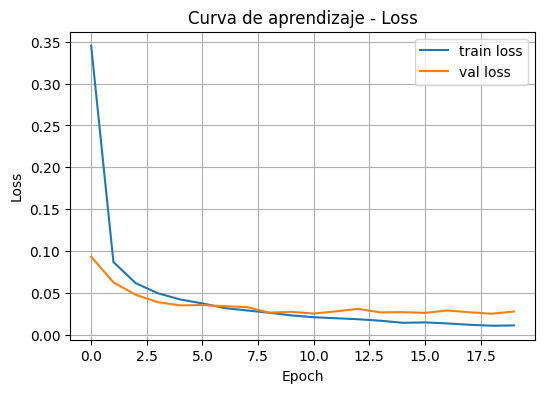

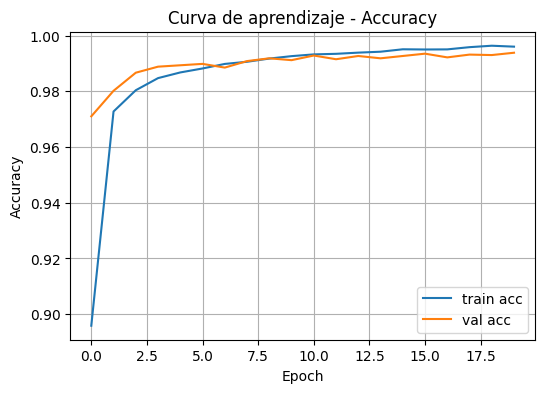

Sugerencia de lectura: mejor val_accuracy = 0.9938. Si hay separación persistente entre train y val, puede haber sobreajuste; si convergen, el modelo generaliza bien.


In [ ]:
hist = best["history"]

set_mpl()
plt.plot(hist["loss"], label="train loss")
plt.plot(hist["val_loss"], label="val loss")
plt.title("Curva de aprendizaje - Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.show()

plt.plot(hist["accuracy"], label="train acc")
plt.plot(hist["val_accuracy"], label="val acc")
plt.title("Curva de aprendizaje - Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.show()

final_va = max(hist["val_accuracy"])
print(f"Sugerencia de lectura: mejor val_accuracy = {final_va:.4f}. "
      "Si hay separación persistente entre train y val, puede haber sobreajuste; "
      "si convergen, el modelo generaliza bien.")


Elegimos **Accuracy** por ser el estándar en MNIST. Para el **intervalo de confianza (95%)**
usamos la aproximación **Wilson** para una proporción: ofrece límites más confiables que
la aproximación normal cuando p está cerca de 0 o 1.


In [ ]:
# Entrada adecuada según el mejor modelo
if best["name"] == "CNN":
    X_test_in = X_test_f[..., None]
else:
    X_test_in = X_test_f

y_prob = best["model"].predict(X_test_in, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

acc = accuracy_score(y_test, y_pred)
ci_low, ci_high = wilson_ci(acc, n=len(y_test))

print(f"Accuracy en Test: {acc:.4f}")
print(f"IC 95% (Wilson): [{ci_low:.4f}, {ci_high:.4f}]")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, digits=4))


Accuracy en Test: 0.9941
IC 95% (Wilson): [0.9924, 0.9954]

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.9959    0.9980    0.9969       980
           1     0.9947    0.9965    0.9956      1135
           2     0.9932    0.9961    0.9947      1032
           3     0.9911    0.9970    0.9941      1010
           4     0.9959    0.9980    0.9969       982
           5     0.9888    0.9910    0.9899       892
           6     0.9989    0.9864    0.9926       958
           7     0.9942    0.9922    0.9932      1028
           8     0.9898    0.9969    0.9934       974
           9     0.9980    0.9881    0.9930      1009

    accuracy                         0.9941     10000
   macro avg     0.9941    0.9940    0.9940     10000
weighted avg     0.9941    0.9941    0.9941     10000



Pronosticamos la clase de `X_test[50]` y `X_test[150]` y mostramos cada imagen.


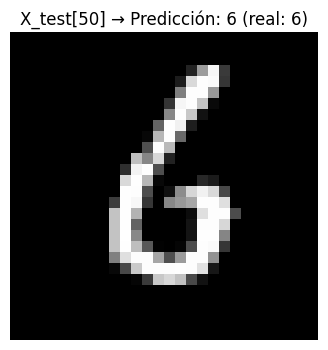

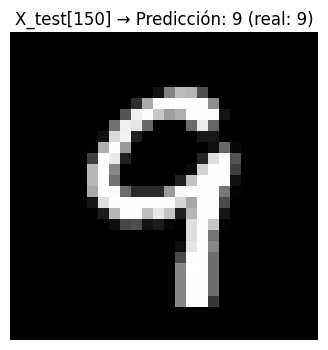

In [ ]:
idxs = [50, 150]
for i in idxs:
    x = X_test_f[i]
    x_in = x[..., None] if best["name"] == "CNN" else x
    x_in = np.expand_dims(x_in, axis=0)
    pred = np.argmax(best["model"].predict(x_in, verbose=0), axis=1)[0]
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f"X_test[{i}] → Predicción: {pred} (real: {y_test[i]})")
    plt.axis('off')
    plt.show()


Entrenamos nuevamente la **misma arquitectura** óptima con **train+val** juntos (más datos → mejor ajuste), y luego:
- Evaluamos en test (opcional para reporte final).
- Guardamos el modelo a disco como `.keras` (o `.h5`).


In [ ]:
# Reentrenar con train+val en la mejor arquitectura/hiperparámetros
X_prod = np.concatenate([X_train, X_val], axis=0)
y_prod = np.concatenate([y_train, y_val], axis=0)

if best["name"] == "CNN":
    X_prod_in = X_prod[..., None]
    model_prod = build_cnn(conv_blocks=best["cfg"]["conv_blocks"],
                           dense_units=best["cfg"]["dense_units"],
                           dropout=best["cfg"]["dropout"])
else:
    X_prod_in = X_prod
    model_prod = build_mlp(hidden_units=best["cfg"]["hu"],
                           dropout=best["cfg"]["dropout"])

model_prod, hist_prod = compile_and_fit(
    model_prod, X_prod_in, y_prod,
    (X_test_f[...,None] if best["name"]=="CNN" else X_test_f), y_test,
    lr=best["cfg"]["lr"], batch_size=best["cfg"]["bs"], epochs=30, patience=5
)

# Evaluación final (reportada a modo informativo)
X_test_in = X_test_f[..., None] if best["name"]=="CNN" else X_test_f
test_probs = model_prod.predict(X_test_in, verbose=0)
test_pred = np.argmax(test_probs, axis=1)
acc_prod = accuracy_score(y_test, test_pred)
ci_l, ci_h = wilson_ci(acc_prod, n=len(y_test))
print(f"[PRODUCCIÓN] Accuracy Test: {acc_prod:.4f} | IC95%: [{ci_l:.4f}, {ci_h:.4f}]")

# Guardado
os.makedirs("model", exist_ok=True)
model_path = "model/mnist_production.keras"
model_prod.save(model_path)
print("Modelo guardado en:", model_path)


Epoch 1/30
469/469 - 47s - 101ms/step - accuracy: 0.8956 - loss: 0.3408 - val_accuracy: 0.9764 - val_loss: 0.0720
Epoch 2/30
469/469 - 46s - 98ms/step - accuracy: 0.9713 - loss: 0.0894 - val_accuracy: 0.9855 - val_loss: 0.0438
Epoch 3/30
469/469 - 82s - 175ms/step - accuracy: 0.9803 - loss: 0.0638 - val_accuracy: 0.9890 - val_loss: 0.0361
Epoch 4/30
469/469 - 46s - 99ms/step - accuracy: 0.9844 - loss: 0.0497 - val_accuracy: 0.9893 - val_loss: 0.0319
Epoch 5/30
469/469 - 81s - 174ms/step - accuracy: 0.9868 - loss: 0.0419 - val_accuracy: 0.9908 - val_loss: 0.0284
Epoch 6/30
469/469 - 45s - 97ms/step - accuracy: 0.9883 - loss: 0.0357 - val_accuracy: 0.9901 - val_loss: 0.0292
Epoch 7/30
469/469 - 83s - 176ms/step - accuracy: 0.9901 - loss: 0.0312 - val_accuracy: 0.9916 - val_loss: 0.0258
Epoch 8/30
469/469 - 82s - 174ms/step - accuracy: 0.9906 - loss: 0.0286 - val_accuracy: 0.9921 - val_loss: 0.0221
Epoch 9/30
469/469 - 82s - 175ms/step - accuracy: 0.9917 - loss: 0.0258 - val_accuracy: 0.9

Para interpretar y acelerar, reducimos a **200 píxeles** usando **Mutual Information (MI)** entre cada píxel (feature) y la etiqueta.
Pasos:
1) Aplanamos imágenes a 784 features.
2) Calculamos MI en `X_train`.
3) Tomamos los **200** índices con mayor MI.
4) **Mapa de calor**: proyectamos la importancia (MI) a 28×28 para visualizar qué regiones aportan más al pronóstico.
> Alternativas (no implementadas aquí por brevedad): **PCA**, **Autoencoders**.


Top-200 idx ejemplo (primeros 20): [356 439 129 493 494 442 292 186 297 525 426 269 301 628 244 466 599 412
 454 653]


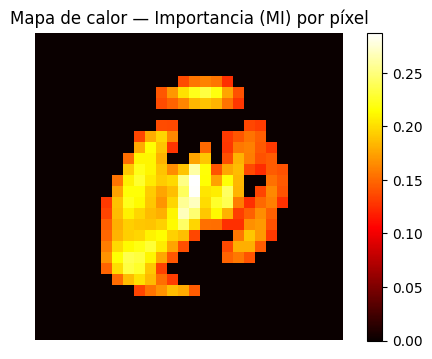

In [ ]:
# 1) Flatten
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat   = X_val.reshape(len(X_val), -1)
X_test_flat  = X_test_f.reshape(len(X_test_f), -1)

# 2) MI por píxel
mi = mutual_info_classif(X_train_flat, y_train, discrete_features=False, random_state=SEED)

# 3) Top-200 features
k = 200
top_idx = np.argsort(mi)[-k:]

print("Top-200 idx ejemplo (primeros 20):", top_idx[:20])

# 4) Heatmap de importancia
mi_map = np.zeros(784)
mi_map[top_idx] = mi[top_idx]
mi_img = mi_map.reshape(28,28)

plt.imshow(mi_img, cmap='hot')
plt.title("Mapa de calor — Importancia (MI) por píxel")
plt.colorbar()
plt.axis('off')
plt.show()


Entrenamos un **MLP ligero** con las 200 features seleccionadas y comparamos Accuracy con el modelo completo.
Justificación: con menos variables se reduce ruido, costo computacional y riesgo de sobreajuste (si las features son informativas).


In [ ]:
# Conjuntos reducidos
X_train_red = X_train_flat[:, top_idx]
X_val_red   = X_val_flat[:, top_idx]
X_test_red  = X_test_flat[:, top_idx]

# Modelo reducido MLP
def build_mlp_reduced(input_dim=200, hidden_units=[256,128], dropout=0.2, num_classes=10):
    inputs = keras.Input(shape=(input_dim,))
    x = inputs
    for u in hidden_units:
        x = layers.Dense(u, activation='relu')(x)
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return keras.Model(inputs, outputs, name="MLP_Reduced")

mlp_red = build_mlp_reduced(input_dim=k, hidden_units=[256,128], dropout=0.3)

mlp_red.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])

es = callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
hist_red = mlp_red.fit(X_train_red, y_train,
                       validation_data=(X_val_red, y_val),
                       epochs=25, batch_size=256, verbose=2,
                       callbacks=[es])

# Evaluación reducida
y_pred_red = np.argmax(mlp_red.predict(X_test_red, verbose=0), axis=1)
acc_red = accuracy_score(y_test, y_pred_red)
ci_l_red, ci_h_red = wilson_ci(acc_red, n=len(y_test))

print(f"[REDUCIDO-200] Accuracy Test: {acc_red:.4f} | IC95%: [{ci_l_red:.4f}, {ci_h_red:.4f}]")


Epoch 1/25
211/211 - 2s - 9ms/step - accuracy: 0.7975 - loss: 0.6359 - val_accuracy: 0.9110 - val_loss: 0.2804
Epoch 2/25
211/211 - 1s - 5ms/step - accuracy: 0.9082 - loss: 0.2997 - val_accuracy: 0.9358 - val_loss: 0.1971
Epoch 3/25
211/211 - 2s - 8ms/step - accuracy: 0.9309 - loss: 0.2273 - val_accuracy: 0.9488 - val_loss: 0.1595
Epoch 4/25
211/211 - 2s - 10ms/step - accuracy: 0.9414 - loss: 0.1907 - val_accuracy: 0.9538 - val_loss: 0.1383
Epoch 5/25
211/211 - 1s - 6ms/step - accuracy: 0.9484 - loss: 0.1650 - val_accuracy: 0.9602 - val_loss: 0.1247
Epoch 6/25
211/211 - 1s - 5ms/step - accuracy: 0.9538 - loss: 0.1482 - val_accuracy: 0.9585 - val_loss: 0.1224
Epoch 7/25
211/211 - 1s - 5ms/step - accuracy: 0.9597 - loss: 0.1327 - val_accuracy: 0.9632 - val_loss: 0.1122
Epoch 8/25
211/211 - 1s - 5ms/step - accuracy: 0.9620 - loss: 0.1235 - val_accuracy: 0.9645 - val_loss: 0.1046
Epoch 9/25
211/211 - 1s - 5ms/step - accuracy: 0.9634 - loss: 0.1164 - val_accuracy: 0.9680 - val_loss: 0.0992


Comparamos el accuracy del mejor modelo completo vs. reducido a 200 variables.
- Si el reducido mantiene (o mejora) performance, indica que las features seleccionadas concentran la mayor información relevante.
- Si cae, puede requerir otro método de selección (PCA, autoencoder) o ajustar el k (por ejemplo 300–400).


In [ ]:
print("=== RESUMEN COMPARATIVO ===")
print(f"Mejor modelo (val)        : {best['name']} | val_acc≈{max(best['history']['val_accuracy']):.4f}")
print(f"Producción (Test, completo): acc={acc_prod:.4f} | IC95%=[{ci_l:.4f}, {ci_h:.4f}]")
print(f"Reducido a 200 (Test)      : acc={acc_red:.4f} | IC95%=[{ci_l_red:.4f}, {ci_h_red:.4f}]")


=== RESUMEN COMPARATIVO ===


NameError: name 'best' is not defined

**Checklist del enunciado:**
- [x] Visualización y EDA
- [x] Preprocesamiento (escalado) y split correcto (train/val/test)
- [x] Búsqueda de hiperparámetros (for loops, sin keras-tuner)
- [x] Entrenamiento y evaluación
- [x] Accuracy explícito + IC 95%
- [x] Curvas de aprendizaje + comentarios
- [x] Predicciones en X_test[50] y X_test[150]
- [x] Modelo de producción entrenado con datos correctos
- [x] Guardado del modelo a archivo
- [x] Reducción de variables a 200 (Mutual Information)
- [x] Mapa de calor de importancia
- [x] Entrenamiento con datos reducidos y **comparación**

**Reproducibilidad:**
- Semillas fijadas.
- Parada temprana y espacios de búsqueda acotados para tiempos razonables.
- Si se quiere mayor precisión, ampliar el espacio de búsqueda y/o épocas.
